# Why Does the Same Doctor Visit Cost So Differently? Medicare Cost Variation Analysis

**Author:** Toyin (Oloruntoba Oluwatoyin)
**Tools:** Python (pandas), SQL (SQLite), matplotlib, Google Colab
**Data:** CMS "Medicare Physician & Other Practitioners - by Provider and Service", 2024 (real public data from data.cms.gov)

---

## The business problem

Imagine I am a data analyst on a health-insurance cost and oversight team. My manager asks me one question:

> **"For the exact same service, why do costs look so different from one provider to another and from one state to another? And where might there be waste or things worth a closer look?"**

To keep the question fair, I picked **one single service**: HCPCS code **99214**, a standard office visit for an existing patient (moderate complexity, about 30 minutes). Because it is the same visit everywhere, any difference in cost is not because the doctors did different procedures.

I compared **four large states: California (CA), New York (NY), Texas (TX) and Ohio (OH)**.

## What I will do in this notebook

1. Load the real CMS data and check that it is what I think it is
2. Clean it and document every choice
3. Use SQL to answer the business questions
4. Build charts
5. Write a plain-language summary of what I found, plus the limits of this data
6. Export small summary tables for a Looker Studio dashboard

## Money columns explained (so the rest makes sense)

| Column | What it means |
|---|---|
| `Avg_Sbmtd_Chrg` | What the provider **billed** (the "list price") |
| `Avg_Mdcr_Alowd_Amt` | What Medicare **allowed** (the approved amount for the visit) |
| `Avg_Mdcr_Pymt_Amt` | What Medicare **actually paid** (the rest is the patient's share) |
| `Avg_Mdcr_Stdzd_Amt` | The allowed amount after **removing local price adjustments** (so states can be compared fairly) |

## Step 1: Load the data and import necessary libraries

Upload the CSV or the zip file

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from google.colab import files

print("Please select the 'Medicare_Physician*.zip' or 'Medicare_Physician*.csv' file to upload:")
uploaded = files.upload()

for filename in uploaded.keys():
    print(f'User uploaded file "{filename}" with length {len(uploaded[filename])} bytes')
    # If it's a zip file, extract it
    if filename.endswith('.zip'):
        with zipfile.ZipFile(filename, 'r') as zip_ref:
            zip_ref.extractall('.')
        print(f'Extracted contents of {filename}')
    # If it's a CSV, it's already in the Colab environment
    elif filename.endswith('.csv'):
        print(f'CSV file {filename} is ready.')


Please select the 'Medicare_Physician*.zip' or 'Medicare_Physician*.csv' file to upload:


Saving Medicare_Physician_Other_Practitioners_by_Provider_and_Service_2024 (9).zip to Medicare_Physician_Other_Practitioners_by_Provider_and_Service_2024 (9).zip
User uploaded file "Medicare_Physician_Other_Practitioners_by_Provider_and_Service_2024 (9).zip" with length 10467467 bytes
Extracted contents of Medicare_Physician_Other_Practitioners_by_Provider_and_Service_2024 (9).zip


In [ ]:
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

# Assuming the CSV is already extracted to /content/ by a previous step
found_csv_file = "/content/Medicare_Physician_Other_Practitioners_by_Provider_and_Service_2024.csv"
df = pd.read_csv(found_csv_file, low_memory=False)
print("Loaded:", found_csv_file)
print("Rows, columns:", df.shape)
df.head(3)

Loaded: /content/Medicare_Physician_Other_Practitioners_by_Provider_and_Service_2024.csv
Rows, columns: (131951, 28)


,Rndrng_NPI,Rndrng_Prvdr_Last_Org_Name,Rndrng_Prvdr_First_Name,Rndrng_Prvdr_MI,Rndrng_Prvdr_Crdntls,Rndrng_Prvdr_Ent_Cd,Rndrng_Prvdr_St1,Rndrng_Prvdr_St2,Rndrng_Prvdr_City,Rndrng_Prvdr_State_Abrvtn,Rndrng_Prvdr_State_FIPS,Rndrng_Prvdr_Zip5,Rndrng_Prvdr_RUCA,Rndrng_Prvdr_RUCA_Desc,Rndrng_Prvdr_Cntry,Rndrng_Prvdr_Type,Rndrng_Prvdr_Mdcr_Prtcptg_Ind,HCPCS_Cd,HCPCS_Desc,HCPCS_Drug_Ind,Place_Of_Srvc,Tot_Benes,Tot_Srvcs,Tot_Bene_Day_Srvcs,Avg_Sbmtd_Chrg,Avg_Mdcr_Alowd_Amt,Avg_Mdcr_Pymt_Amt,Avg_Mdcr_Stdzd_Amt
0,1992998645,Marupudi,Seshasree,NaN,MD,I,129 Vision Park Blvd,Ste 300,Shenandoah,TX,48,77384,1.1,Secondary flow 30% to <50% to a larger urbaniz...,US,Internal Medicine,Y,99214,Established patient office or other outpatient...,N,O,305,979.0,979,309.000000,120.753034,84.484178,89.020603
1,1992989206,Ramirez,Peter,B,MD,I,1001 Pennsylvania Ave,NaN,Fort Worth,TX,48,76104,1.0,Metropolitan area core: primary flow within an...,US,Nephrology,Y,99214,Established patient office or other outpatient...,N,O,122,191.0,191,295.548063,108.499005,67.830733,84.025236
2,1992989206,Ramirez,Peter,B,MD,I,1001 Pennsylvania Ave,NaN,Fort Worth,TX,48,76104,1.0,Metropolitan area core: primary flow within an...,US,Nephrology,Y,99214,Established patient office or other outpatient...,N,F,28,48.0,48,193.632500,95.811250,71.856667,70.528333


## Step 2: Check the data before trusting it

Before any analysis I want to confirm the file only contains what I asked for, and look for problems.

In [ ]:
print("States in file:")
print(df["Rndrng_Prvdr_State_Abrvtn"].value_counts(), "\n")

print("Procedure codes in file:", df["HCPCS_Cd"].unique())
print("Description:", df["HCPCS_Desc"].unique()[0], "\n")

print("Place of service (O = office, F = facility such as a hospital outpatient department):")
print(df["Place_Of_Srvc"].value_counts(), "\n")

print("Provider type (I = individual, O = organisation):")
print(df["Rndrng_Prvdr_Ent_Cd"].value_counts())

States in file:
Rndrng_Prvdr_State_Abrvtn
CA    41574
TX    35440
NY    32810
OH    22127
Name: count, dtype: int64 

Procedure codes in file: [99214]
Description: Established patient office or other outpatient visit with moderate level of decision making, if using time, 30 minutes or more 

Place of service (O = office, F = facility such as a hospital outpatient department):
Place_Of_Srvc
O    115547
F     16404
Name: count, dtype: int64 

Provider type (I = individual, O = organisation):
Rndrng_Prvdr_Ent_Cd
I    131949
O         2
Name: count, dtype: int64


In [ ]:
# Missing values, duplicates, and odd values
missing = df.isna().sum()
print("Columns with missing values:")
print(missing[missing > 0], "\n")

print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicate provider + code + place-of-service rows:",
      df.duplicated(["Rndrng_NPI", "HCPCS_Cd", "Place_Of_Srvc"]).sum(), "\n")

money = ["Avg_Sbmtd_Chrg", "Avg_Mdcr_Alowd_Amt", "Avg_Mdcr_Pymt_Amt", "Avg_Mdcr_Stdzd_Amt"]
print(df[money].describe().round(2), "\n")

print("Rows where Medicare paid $0:", (df["Avg_Mdcr_Pymt_Amt"] == 0).sum())
print("Rows where billed charge is LOWER than allowed amount:", (df["Avg_Sbmtd_Chrg"] < df["Avg_Mdcr_Alowd_Amt"]).sum())

Columns with missing values:
Rndrng_Prvdr_First_Name         2
Rndrng_Prvdr_MI             49231
Rndrng_Prvdr_Crdntls         8852
Rndrng_Prvdr_St2           101652
Rndrng_Prvdr_RUCA              53
Rndrng_Prvdr_RUCA_Desc         53
dtype: int64 

Fully duplicated rows: 0
Duplicate provider + code + place-of-service rows: 0 

       Avg_Sbmtd_Chrg  Avg_Mdcr_Alowd_Amt  Avg_Mdcr_Pymt_Amt  Avg_Mdcr_Stdzd_Amt
count       131951.00           131951.00          131951.00           131951.00
mean           317.10              118.48              83.75               81.65
std            167.97               19.88              17.45               12.71
min             55.00               31.83               0.00                0.00
25%            200.00              103.29              71.86               72.78
50%            275.00              121.13              84.48               84.31
75%            371.72              134.58              96.54               91.76
max           6240.00   

**What the checks tell me**

- The file contains only the four states and only code 99214, so my filter worked.
- No duplicates.
- The missing values are only in optional fields (middle initial, address line 2, credentials, rural-urban code). None of the money columns are missing.
- 121 rows show a billed price below the Medicare approved amount. That can happen (providers can bill less than the fee schedule), so I keep them.
- A handful of rows show $0 paid by Medicare. That is unusual for an office visit, so I treat them as data oddities and remove them in the cleaning step.

## Step 3: Clean the data

I keep only the columns I need, remove the odd rows, and create the columns I will analyse.

In [ ]:
keep = ["Rndrng_NPI", "Rndrng_Prvdr_Type", "Rndrng_Prvdr_State_Abrvtn", "Rndrng_Prvdr_City",
        "Rndrng_Prvdr_RUCA_Desc", "Place_Of_Srvc", "Tot_Benes", "Tot_Srvcs",
        "Avg_Sbmtd_Chrg", "Avg_Mdcr_Alowd_Amt", "Avg_Mdcr_Pymt_Amt", "Avg_Mdcr_Stdzd_Amt"]
d = df[keep].copy()
d.columns = ["npi", "provider_type", "state", "city", "area_type", "place",
             "patients", "services", "billed", "allowed", "paid", "standardized"]

before = len(d)

# 1) remove rows where Medicare paid $0 (data oddity)
d = d[d["paid"] > 0]
print("Removed rows with $0 paid:", before - len(d))

# 2) readable labels
d["place"] = d["place"].map({"O": "Office", "F": "Facility"})

# 3) new columns
d["billed_to_allowed"] = d["billed"] / d["allowed"]     # how many times the billed price is above the approved price
d["total_paid"] = d["paid"] * d["services"]             # total Medicare dollars for that provider's 99214 visits

print("Rows after cleaning:", len(d))
d.head(3)

Removed rows with $0 paid: 3
Rows after cleaning: 131948


,npi,provider_type,state,city,area_type,place,patients,services,billed,allowed,paid,standardized,billed_to_allowed,total_paid
0,1992998645,Internal Medicine,TX,Shenandoah,Secondary flow 30% to <50% to a larger urbaniz...,Office,305,979.0,309.000000,120.753034,84.484178,89.020603,2.558942,82710.01
1,1992989206,Nephrology,TX,Fort Worth,Metropolitan area core: primary flow within an...,Office,122,191.0,295.548063,108.499005,67.830733,84.025236,2.723970,12955.67
2,1992989206,Nephrology,TX,Fort Worth,Metropolitan area core: primary flow within an...,Facility,28,48.0,193.632500,95.811250,71.856667,70.528333,2.020979,3449.12


**Cleaning choices, in plain words**

- I removed only rows I could justify removing (the $0 payments). I did **not** remove high-billing providers, because those are exactly what this project is looking for.
- I created `billed_to_allowed`. A value of 3.0 means the provider billed three times what Medicare approved.

## Step 4: Load into SQL and ask business questions

I load the clean table into SQLite so I can use SQL, the same way I would query a database at work.

In [ ]:
conn = sqlite3.connect(":memory:")
d.to_sql("visits", conn, index=False, if_exists="replace")
print(pd.read_sql("SELECT COUNT(*) AS rows_in_table FROM visits", conn))

   rows_in_table
0         131948


### Question 1: How do the four states compare?

In [ ]:
q1 = '''
SELECT state,
       COUNT(DISTINCT npi)               AS providers,
       ROUND(AVG(billed), 2)             AS avg_billed,
       ROUND(AVG(allowed), 2)            AS avg_allowed,
       ROUND(AVG(paid), 2)               AS avg_paid,
       ROUND(AVG(standardized), 2)       AS avg_standardized,
       ROUND(AVG(billed) / AVG(allowed), 2) AS billed_to_allowed
FROM visits
GROUP BY state
ORDER BY avg_billed DESC
'''
state_summary = pd.read_sql(q1, conn)
state_summary

,state,providers,avg_billed,avg_allowed,avg_paid,avg_standardized,billed_to_allowed
0,NY,31514,355.47,123.52,89.05,82.41,2.88
1,CA,39669,349.53,127.13,90.50,83.96,2.75
2,OH,20545,276.04,103.24,70.53,76.67,2.67
3,TX,34253,269.19,113.21,79.18,81.37,2.38


### Question 2: How much of the state difference is just local price adjustment?

Medicare adjusts payments for local costs (rent, wages). The **standardized** amount removes that adjustment. If a state looks expensive on `allowed` but not on `standardized`, the gap is mostly local pricing and not a difference in the service itself.

In [ ]:
q2 = '''
SELECT state,
       ROUND(AVG(allowed), 2)      AS avg_allowed,
       ROUND(AVG(standardized), 2) AS avg_standardized,
       ROUND(AVG(allowed) - AVG(standardized), 2) AS local_adjustment_effect
FROM visits
GROUP BY state
ORDER BY avg_allowed DESC
'''
pd.read_sql(q2, conn)

,state,avg_allowed,avg_standardized,local_adjustment_effect
0,CA,127.13,83.96,43.17
1,NY,123.52,82.41,41.10
2,TX,113.21,81.37,31.84
3,OH,103.24,76.67,26.57


### Question 3: Does the setting matter? (Office vs Facility)

In [ ]:
q3 = '''
SELECT place,
       COUNT(*)                 AS rows_,
       ROUND(AVG(billed), 2)    AS avg_billed,
       ROUND(AVG(allowed), 2)   AS avg_allowed,
       ROUND(AVG(paid), 2)      AS avg_paid
FROM visits
GROUP BY place
'''
pd.read_sql(q3, conn)

,place,rows_,avg_billed,avg_allowed,avg_paid
0,Facility,16404,328.01,93.15,67.84
1,Office,115544,315.56,122.08,86.01


### Question 4: Which provider types bill highest compared to what Medicare approves?

I only include provider types with at least 200 providers so a few unusual providers cannot distort the result.

In [ ]:
q4 = '''
SELECT provider_type,
       COUNT(DISTINCT npi)               AS providers,
       ROUND(AVG(billed), 2)             AS avg_billed,
       ROUND(AVG(allowed), 2)            AS avg_allowed,
       ROUND(AVG(billed) / AVG(allowed), 2) AS billed_to_allowed
FROM visits
GROUP BY provider_type
HAVING COUNT(DISTINCT npi) >= 200
ORDER BY billed_to_allowed DESC
'''
type_summary = pd.read_sql(q4, conn)
type_summary.head(10)

,provider_type,providers,avg_billed,avg_allowed,billed_to_allowed
0,Medical Oncology,1090,391.57,115.31,3.40
1,Radiation Oncology,740,374.45,111.60,3.36
2,Geriatric Medicine,306,397.25,118.92,3.34
3,Hematology,225,373.99,112.73,3.32
4,Gynecological Oncology,259,393.60,119.41,3.30
5,Surgical Oncology,245,390.24,119.29,3.27
6,Interventional Pain Management,339,408.04,124.81,3.27
7,Neurosurgery,899,395.07,122.77,3.22
8,Pain Management,723,391.45,123.34,3.17
9,Anesthesiology,626,386.90,122.24,3.17


### Question 5: Who are the extreme billers? (Where should someone look closer?)

I flag providers who billed **more than 5 times** what Medicare approved, and I only count providers with at least 30 patients so it is not a tiny-sample effect.

In [ ]:
q5 = '''
SELECT state,
       COUNT(*)                                                    AS provider_rows,
       SUM(CASE WHEN billed_to_allowed > 5 THEN 1 ELSE 0 END)      AS extreme_billers,
       ROUND(100.0 * SUM(CASE WHEN billed_to_allowed > 5 THEN 1 ELSE 0 END) / COUNT(*), 2) AS pct_extreme
FROM visits
WHERE patients >= 30
GROUP BY state
ORDER BY pct_extreme DESC
'''
extreme_by_state = pd.read_sql(q5, conn)
extreme_by_state

,state,provider_rows,extreme_billers,pct_extreme
0,OH,16019,2221,13.86
1,CA,31189,2782,8.92
2,NY,23168,1281,5.53
3,TX,26422,280,1.06


In [ ]:
q6 = '''
SELECT npi, provider_type, state, city, place, patients, services,
       ROUND(billed, 2) AS billed, ROUND(allowed, 2) AS allowed,
       ROUND(billed_to_allowed, 1) AS billed_to_allowed
FROM visits
WHERE patients >= 30
ORDER BY billed_to_allowed DESC
LIMIT 10
'''
top_extreme = pd.read_sql(q6, conn)
top_extreme

### Question 5b: Are the "extreme billers" really many different providers, or the same price repeated?

When I looked at the top of the list I noticed the same billed amounts showing up again and again. So I check which billed price is most common among the extreme billers in each state.

In [ ]:
q6b = '''
SELECT state,
       ROUND(billed, 0)  AS billed_price,
       COUNT(*)          AS provider_rows
FROM visits
WHERE patients >= 30 AND billed_to_allowed > 5
GROUP BY state, ROUND(billed, 0)
'''
rep = pd.read_sql(q6b, conn)
rep["share_of_state_extremes_pct"] = (100 * rep["provider_rows"] / rep.groupby("state")["provider_rows"].transform("sum")).round(1)
rep = rep.sort_values(["state", "provider_rows"], ascending=[True, False]).groupby("state").head(2)
rep

,state,billed_price,provider_rows,share_of_state_extremes_pct
190,CA,858.0,1189,42.7
50,CA,577.0,479,17.2
353,NY,688.0,278,21.7
317,NY,545.0,188,14.7
497,OH,624.0,1942,87.4
498,OH,625.0,43,1.9
617,TX,894.0,20,7.1
572,TX,657.0,17,6.1


**Why this matters:** if one price makes up a large share of a state's extreme billers, then it is probably one big organisation or billing system applying a single standard list price across all its providers. That is a very different story from thousands of individual doctors each choosing to overcharge. It tells the oversight team to look at a **few organisations' price lists**, not at thousands of individual providers. (This is my reading of the pattern. The data itself does not name the organisations.)

### Question 6: Where do the Medicare dollars actually go?

A few providers do a very large number of these visits. This shows how concentrated the spending is.

In [ ]:
q7 = '''
SELECT provider_type,
       ROUND(SUM(total_paid) / 1000000.0, 1) AS total_paid_million_usd,
       SUM(services)                         AS total_visits
FROM visits
GROUP BY provider_type
ORDER BY total_paid_million_usd DESC
LIMIT 8
'''
spend_by_type = pd.read_sql(q7, conn)
spend_by_type

,provider_type,total_paid_million_usd,total_visits
0,Internal Medicine,356.2,4041909.0
1,Family Practice,304.6,3678587.8
2,Cardiology,236.4,2514200.0
3,Nurse Practitioner,190.6,2678378.1
4,Physician Assistant,103.3,1395013.0
5,Urology,80.0,839641.0
6,Ophthalmology,79.4,861297.1
7,Hematology-Oncology,78.7,845179.0


## Step 5: Charts

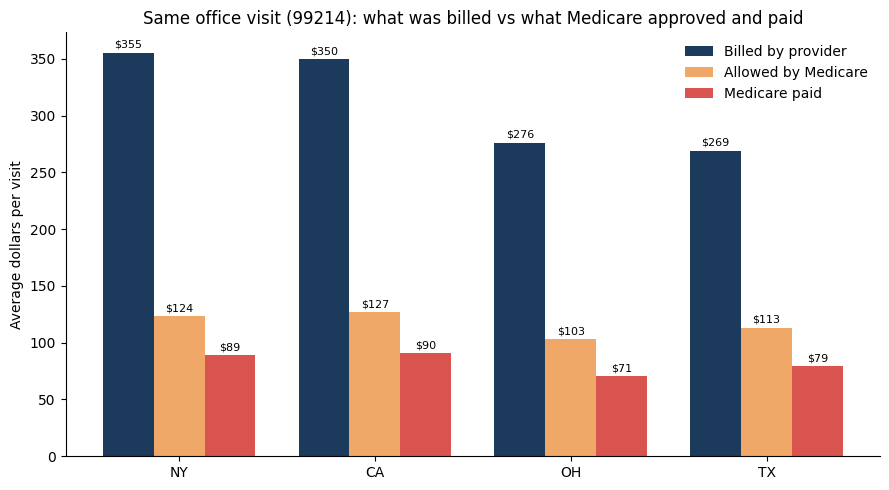

In [ ]:
NAVY, RED, ORANGE, GREY = "#1B3A5C", "#D9534F", "#F0A868", "#9AA5B1"

# Chart 1: billed vs allowed vs paid by state
s = state_summary.sort_values("avg_billed", ascending=False)
x = np.arange(len(s)); w = 0.26
fig, ax = plt.subplots(figsize=(9, 5))
b1 = ax.bar(x - w, s["avg_billed"], w, label="Billed by provider", color=NAVY)
b2 = ax.bar(x, s["avg_allowed"], w, label="Allowed by Medicare", color=ORANGE)
b3 = ax.bar(x + w, s["avg_paid"], w, label="Medicare paid", color=RED)
for bars in (b1, b2, b3):
    ax.bar_label(bars, fmt="$%.0f", fontsize=8, padding=2)
ax.set_xticks(x); ax.set_xticklabels(s["state"])
ax.set_ylabel("Average dollars per visit")
ax.set_title("Same office visit (99214): what was billed vs what Medicare approved and paid")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("chart1_state_costs.png", dpi=150); plt.show()

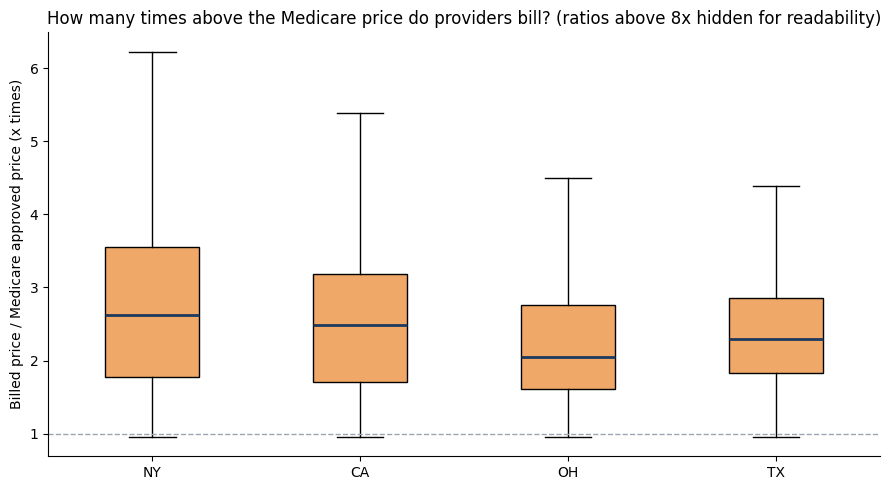

In [ ]:
# Chart 2: how spread out is the billed-to-allowed ratio in each state?
order = state_summary.sort_values("billed_to_allowed", ascending=False)["state"].tolist()
data = [d.loc[(d["state"] == st) & (d["billed_to_allowed"] <= 8), "billed_to_allowed"] for st in order]
fig, ax = plt.subplots(figsize=(9, 5))
bp = ax.boxplot(data, patch_artist=True, showfliers=False)
ax.set_xticklabels(order)
for patch in bp["boxes"]:
    patch.set_facecolor(ORANGE)
for med in bp["medians"]:
    med.set_color(NAVY); med.set_linewidth(2)
ax.axhline(1, color=GREY, linestyle="--", linewidth=1)
ax.set_ylabel("Billed price / Medicare approved price (x times)")
ax.set_title("How many times above the Medicare price do providers bill? (ratios above 8x hidden for readability)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("chart2_ratio_spread.png", dpi=150); plt.show()

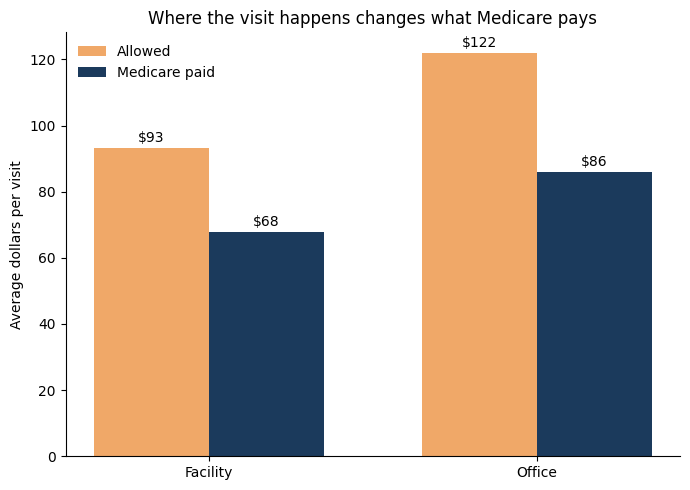

In [ ]:
# Chart 3: office vs facility
p = pd.read_sql("SELECT place, ROUND(AVG(allowed),2) AS allowed, ROUND(AVG(paid),2) AS paid FROM visits GROUP BY place", conn)
x = np.arange(len(p)); w = 0.35
fig, ax = plt.subplots(figsize=(7, 5))
c1 = ax.bar(x - w/2, p["allowed"], w, label="Allowed", color=ORANGE)
c2 = ax.bar(x + w/2, p["paid"], w, label="Medicare paid", color=NAVY)
ax.bar_label(c1, fmt="$%.0f", padding=2); ax.bar_label(c2, fmt="$%.0f", padding=2)
ax.set_xticks(x); ax.set_xticklabels(p["place"])
ax.set_ylabel("Average dollars per visit")
ax.set_title("Where the visit happens changes what Medicare pays")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("chart3_office_vs_facility.png", dpi=150); plt.show()

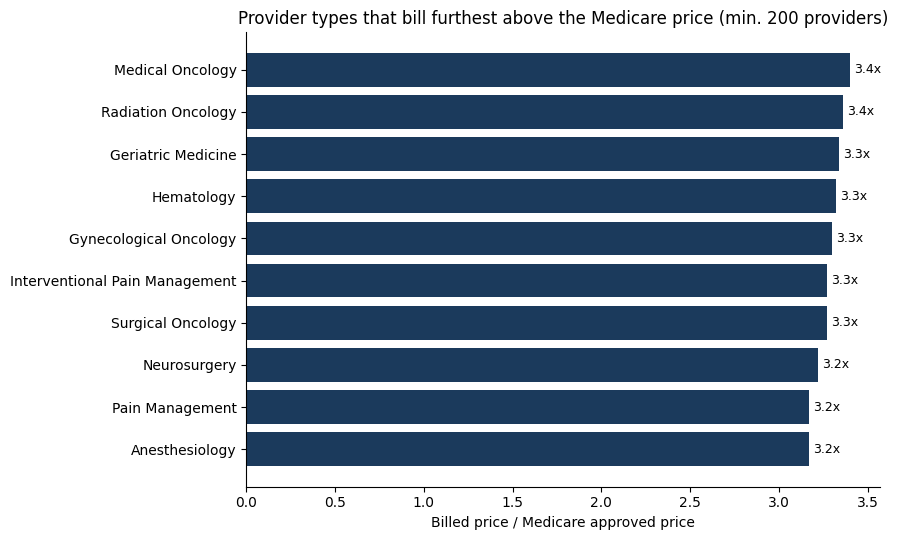

In [ ]:
# Chart 4: provider types with the highest billed-to-allowed ratio
t = type_summary.head(10).sort_values("billed_to_allowed")
fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.barh(t["provider_type"], t["billed_to_allowed"], color=NAVY)
ax.bar_label(bars, fmt="%.1fx", padding=3, fontsize=9)
ax.set_xlabel("Billed price / Medicare approved price")
ax.set_title("Provider types that bill furthest above the Medicare price (min. 200 providers)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("chart4_provider_types.png", dpi=150); plt.show()

## Step 6: Export summary tables for the Looker Studio dashboard

In [ ]:
state_summary.to_csv("state_summary.csv", index=False)
type_summary.to_csv("provider_type_summary.csv", index=False)
extreme_by_state.to_csv("extreme_billers_by_state.csv", index=False)
spend_by_type.to_csv("spend_by_provider_type.csv", index=False)
print("Saved 4 summary files. In Colab, open the folder icon on the left, tap each file, and download them.")

Saved 4 summary files. In Colab, open the folder icon on the left, tap each file, and download them.


## Step 7: Plain-language summary (numbers fill in automatically from the real data)

In [ ]:
overall_ratio = d["billed"].mean() / d["allowed"].mean()
hi = state_summary.sort_values("avg_billed", ascending=False).iloc[0]
lo = state_summary.sort_values("avg_billed", ascending=True).iloc[0]
std = d.groupby("state")["standardized"].mean()
std_gap = (std.max() - std.min()) / std.min() * 100
allowed_state = d.groupby("state")["allowed"].mean()
allowed_gap = (allowed_state.max() - allowed_state.min()) / allowed_state.min() * 100
bill_gap = (hi["avg_billed"] - lo["avg_billed"]) / lo["avg_billed"] * 100
off = d[d.place == "Office"]["paid"].mean(); fac = d[d.place == "Facility"]["paid"].mean()
ext_all = (d[d.patients >= 30]["billed_to_allowed"] > 5).mean() * 100
top_type = type_summary.iloc[0]

print(f'''
WHAT I FOUND (HCPCS 99214, CA / NY / TX / OH, 2024 Medicare data)

1. On average, providers billed about {overall_ratio:.1f}x what Medicare approved
   (about ${d["billed"].mean():.0f} billed vs ${d["allowed"].mean():.0f} approved).

2. Billing differs a lot by state. {hi["state"]} providers billed the most (about ${hi["avg_billed"]:.0f}),
   {lo["state"]} the least (about ${lo["avg_billed"]:.0f}). That is a {bill_gap:.0f}% gap for the exact same visit.

3. The Medicare-approved amount differs by only about {allowed_gap:.0f}% between the highest and lowest state,
   and after removing local price adjustments the gap shrinks to about {std_gap:.0f}%.
   So the state differences in what Medicare pays are mostly local price adjustments,
   while the bigger gap is in what providers choose to bill.

4. Where the visit happens matters. Medicare paid about ${off:.0f} on average in an office
   and about ${fac:.0f} in a facility.

5. About {ext_all:.1f}% of providers (with at least 30 patients) billed more than 5x the Medicare price.
   The provider type with the highest billed-to-allowed ratio (min. 200 providers) was
   {top_type["provider_type"]} at {top_type["billed_to_allowed"]:.1f}x.

6. The extreme billers are concentrated. In several states one repeated billed price makes up a big share of them
   (see Question 5b), which points to a few organisations' standard price lists more than to thousands of
   individual providers.
''')


WHAT I FOUND (HCPCS 99214, CA / NY / TX / OH, 2024 Medicare data)

1. On average, providers billed about 2.7x what Medicare approved
   (about $317 billed vs $118 approved).

2. Billing differs a lot by state. NY providers billed the most (about $355),
   TX the least (about $269). That is a 32% gap for the exact same visit.

3. The Medicare-approved amount differs by only about 23% between the highest and lowest state,
   and after removing local price adjustments the gap shrinks to about 10%.
   So the state differences in what Medicare pays are mostly local price adjustments,
   while the bigger gap is in what providers choose to bill.

4. Where the visit happens matters. Medicare paid about $86 on average in an office
   and about $68 in a facility.

5. About 6.8% of providers (with at least 30 patients) billed more than 5x the Medicare price.
   The provider type with the highest billed-to-allowed ratio (min. 200 providers) was
   Medical Oncology at 3.4x.

6. The extreme billers

In [ ]:
place_summary = pd.read_sql("""
SELECT place, ROUND(AVG(billed),2) AS avg_billed,
       ROUND(AVG(allowed),2) AS avg_allowed,
              ROUND(AVG(paid),2) AS avg_paid
              FROM visits GROUP BY place""", conn)
place_summary.to_csv("office_vs_facility.csv", index=False)

rep.to_csv("repeated_prices.csv", index=False)
print("Saved 2 more files")

Saved 2 more files


## Step 8: Limits of this analysis (honest notes)

- **Billed is not paid.** Medicare pays its approved amount whatever the provider bills. So a high billed price does **not** mean Medicare overpaid. It matters more for patients without insurance, out-of-network care, and price negotiation with private insurers.
- **Only four states and one procedure.** I cannot say anything about the whole US or other services.
- **Medicare only.** This is patients on Medicare, mainly older adults, so it may not match what private insurance pays.
- **Averages hide detail.** Each row is a provider's average across their patients. It does not show how sick those patients were.
- **Higher billing is not proof of wrongdoing.** It is a reason to look closer, not a conclusion.
- **2024 data.** One year only, so I cannot show trends over time.

## Recommendations (what I would tell the manager)

1. **Focus oversight on the extreme tail**, not on all providers. Most billing sits in a normal range. Reviewing the small group that bills far above the rest is cheaper and more useful than a broad audit.
2. **Compare providers within the same state and setting.** Because local price adjustments and office-vs-facility rules change payment, fair comparisons must hold those two things constant.
3. **Use the billed-to-allowed ratio as a screening flag.** It is simple, easy to explain, and can be tracked every year.
4. **Next step:** repeat this for other common codes and add earlier years to see whether the gaps are growing.

---
*Data source: Centers for Medicare & Medicaid Services (CMS), Medicare Physician & Other Practitioners - by Provider and Service, 2024, via data.cms.gov.*